In [32]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/div456/indian-saree-patterns/README.dataset.txt
/kaggle/input/datasets/div456/indian-saree-patterns/README.roboflow.txt
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi/images7_jpg.rf.548124a6f72034f6d9d68a5ee7a0ec38.jpg
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi/X2A4519_321be3c6-86a5-40a0-b208-6183f2290c91_jpg.rf.a5fe3966dcd7917a759342797b9ca3a8.jpg
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi/images138_jpg.rf.0532a3771bb1b61fa0b473388efbe1cc.jpg
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi/images168_jpg.rf.d64adabba8f41b5f3ab9878d33be6474.jpg
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi/images172_jpg.rf.df69457214f062fabc3abc88494e8725.jpg
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi/IF1B1HM123050602_Pink_Banarasi_Silk_Fabric_jpg.rf.cfb3c7cd97909675586b9321f0e135d3.jpg
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banaras

In [33]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(f"\n📁 {root}")
    for file in files[:10]:
        print("   ", file)


📁 /kaggle/input

📁 /kaggle/input/datasets

📁 /kaggle/input/datasets/div456

📁 /kaggle/input/datasets/div456/indian-saree-patterns
    README.dataset.txt
    README.roboflow.txt

📁 /kaggle/input/datasets/div456/indian-saree-patterns/valid

📁 /kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi
    images7_jpg.rf.548124a6f72034f6d9d68a5ee7a0ec38.jpg
    X2A4519_321be3c6-86a5-40a0-b208-6183f2290c91_jpg.rf.a5fe3966dcd7917a759342797b9ca3a8.jpg
    images138_jpg.rf.0532a3771bb1b61fa0b473388efbe1cc.jpg
    images168_jpg.rf.d64adabba8f41b5f3ab9878d33be6474.jpg
    images172_jpg.rf.df69457214f062fabc3abc88494e8725.jpg
    IF1B1HM123050602_Pink_Banarasi_Silk_Fabric_jpg.rf.cfb3c7cd97909675586b9321f0e135d3.jpg
    images142_jpg.rf.bbbec6ce70a0941c05f7b553dfc851f3.jpg
    images29_jpg.rf.5eddd70104f847e7469df48943649f6e.jpg
    T285-PureSoftSatinShikargahFabricRed-3709_1200x_jpg.rf.0f1380d4b049b92aafc6c0aeb585f094.jpg
    image_debfd6b2-0e78-4def-9bb0-8171df052c9b_jpg.rf.4fa0cfe891f6

In [34]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for f in files[:10]:
        print("   ", f)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/div456
/kaggle/input/datasets/div456/indian-saree-patterns
    README.dataset.txt
    README.roboflow.txt
/kaggle/input/datasets/div456/indian-saree-patterns/valid
/kaggle/input/datasets/div456/indian-saree-patterns/valid/Banarasi
    images7_jpg.rf.548124a6f72034f6d9d68a5ee7a0ec38.jpg
    X2A4519_321be3c6-86a5-40a0-b208-6183f2290c91_jpg.rf.a5fe3966dcd7917a759342797b9ca3a8.jpg
    images138_jpg.rf.0532a3771bb1b61fa0b473388efbe1cc.jpg
    images168_jpg.rf.d64adabba8f41b5f3ab9878d33be6474.jpg
    images172_jpg.rf.df69457214f062fabc3abc88494e8725.jpg
    IF1B1HM123050602_Pink_Banarasi_Silk_Fabric_jpg.rf.cfb3c7cd97909675586b9321f0e135d3.jpg
    images142_jpg.rf.bbbec6ce70a0941c05f7b553dfc851f3.jpg
    images29_jpg.rf.5eddd70104f847e7469df48943649f6e.jpg
    T285-PureSoftSatinShikargahFabricRed-3709_1200x_jpg.rf.0f1380d4b049b92aafc6c0aeb585f094.jpg
    image_debfd6b2-0e78-4def-9bb0-8171df052c9b_jpg.rf.4fa0cfe891f6dbfe2cd442e44223a1

In [35]:
import os, collections

roots = ["/kaggle/input/datasets/jeevshree", "/kaggle/input/datasets/div456"]
for root in roots:
    print("=" * 80, "\n", root)
    for dp, dn, fn in os.walk(root):
        depth = dp[len(root):].count(os.sep)
        exts = collections.Counter(os.path.splitext(f)[1].lower() for f in fn)
        if depth <= 4 and (dn or fn):
            print(f"{'  '*depth}{os.path.basename(dp)} | subfolders: {len(dn)} | files: {len(fn)} | types: {dict(exts)} | e.g. {fn[:3]}")
        if depth > 4:
            dn[:] = []   # don't descend further

# any zip / csv / json label files anywhere
print("\nZIP/CSV/JSON files:")
for root in roots:
    for dp, dn, fn in os.walk(root):
        for f in fn:
            if f.lower().endswith((".zip", ".csv", ".json", ".txt", ".xlsx")):
                print(os.path.join(dp, f))

 /kaggle/input/datasets/jeevshree
jeevshree | subfolders: 1 | files: 0 | types: {} | e.g. []
  deeplure-private-exercise-data | subfolders: 1 | files: 0 | types: {} | e.g. []
    drive-download-20261005T080652Z-1-001 | subfolders: 1 | files: 0 | types: {} | e.g. []
      handloom_sarees | subfolders: 0 | files: 165 | types: {'.jpg': 165} | e.g. ['img_568910.jpg', 'img_586537.jpg', 'img_357974.jpg']
 /kaggle/input/datasets/div456
div456 | subfolders: 1 | files: 0 | types: {} | e.g. []
  indian-saree-patterns | subfolders: 3 | files: 2 | types: {'.txt': 2} | e.g. ['README.dataset.txt', 'README.roboflow.txt']
    valid | subfolders: 4 | files: 0 | types: {} | e.g. []
      Banarasi | subfolders: 0 | files: 43 | types: {'.jpg': 43} | e.g. ['images7_jpg.rf.548124a6f72034f6d9d68a5ee7a0ec38.jpg', 'X2A4519_321be3c6-86a5-40a0-b208-6183f2290c91_jpg.rf.a5fe3966dcd7917a759342797b9ca3a8.jpg', 'images138_jpg.rf.0532a3771bb1b61fa0b473388efbe1cc.jpg']
      Pichwai | subfolders: 0 | files: 24 | types:

In [36]:
import os

DEEPLURE_DIR = "/kaggle/input/datasets/jeevshree/deeplure-private-exercise-data/drive-download-20261005T080652Z-1-001/handloom_sarees"

deeplure_images = [
    f for f in os.listdir(DEEPLURE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("DeepLure images:", len(deeplure_images))

DeepLure images: 165


In [37]:
import os

DATA_DIR = "/kaggle/input/datasets/jeevshree/deeplure-private-exercise-data/drive-download-20261005T080652Z-1-001/handloom_sarees"

files = os.listdir(DATA_DIR)

print("Number of files:", len(files))
print("\nFirst 20 files:")

for f in files[:20]:
    print(f)

Number of files: 165

First 20 files:
img_568910.jpg
img_586537.jpg
img_357974.jpg
img_354459.jpg
img_804542.jpg
img_524137.jpg
img_275183.jpg
img_927463.jpg
img_339968.jpg
img_246854.jpg
img_987571.jpg
img_669675.jpg
h_img_76108.jpg
img_578936.jpg
img_341437.jpg
img_874118.jpg
img_897203.jpg
img_142355.jpg
img_917853.jpg
img_337700.jpg


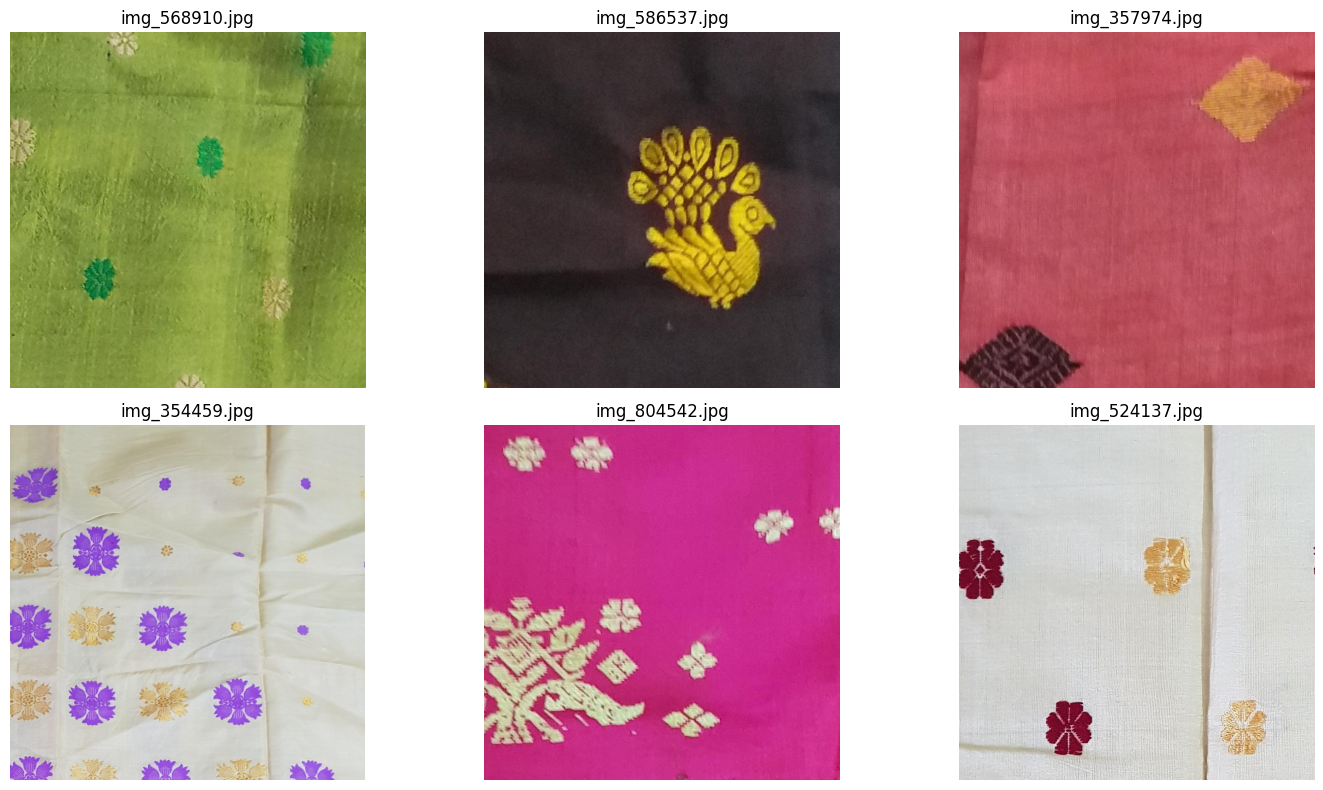

In [38]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Show the first 6 images
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, filename in zip(axes.ravel(), files[:6]):
    img = Image.open(os.path.join(DATA_DIR, filename))
    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [39]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU: True
GPU: Tesla T4


In [40]:
import os

DEEPLURE_DIR = "/kaggle/input/datasets/jeevshree/deeplure-private-exercise-data/drive-download-20261005T080652Z-1-001/handloom_sarees"

SAREE_DIR = "/kaggle/input/datasets/div456/indian-saree-patterns"

print("DeepLure:", len(os.listdir(DEEPLURE_DIR)))
print("Saree dataset folders:", os.listdir(SAREE_DIR))

DeepLure: 165
Saree dataset folders: ['README.dataset.txt', 'README.roboflow.txt', 'valid', 'test', 'train']


In [41]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomResizedCrop(
        224,
        scale=(0.7, 1.0)
    ),

    # Major color changes
    transforms.ColorJitter(
        brightness=0.5,
        contrast=0.4,
        saturation=0.8,
        hue=0.5
    ),

    transforms.RandomGrayscale(p=0.25),

    transforms.RandomHorizontalFlip(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [42]:
print(train_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    ColorJitter(brightness=(0.5, 1.5), contrast=(0.6, 1.4), saturation=(0.19999999999999996, 1.8), hue=(-0.5, 0.5))
    RandomGrayscale(p=0.25)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [43]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = ResNet18_Weights.DEFAULT
backbone = resnet18(weights=weights)

feature_dim = backbone.fc.in_features

backbone.fc = nn.Identity()

class SareeEmbeddingModel(nn.Module):
    def __init__(self, backbone, feature_dim, embedding_dim=128):
        super().__init__()

        self.backbone = backbone

        self.embedding = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, embedding_dim)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.embedding(x)

        # L2-normalized embedding
        x = nn.functional.normalize(x, p=2, dim=1)

        return x

model = SareeEmbeddingModel(
    backbone,
    feature_dim,
    embedding_dim=128
).to(device)

print(model)

SareeEmbeddingModel(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=Tr

In [44]:
import os
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class SareePairDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.transform = transform
        self.samples = []

        # Each class folder is treated as a group of visually related designs.
        for split in ["train", "valid", "test"]:
            split_dir = os.path.join(root_dir, split)

            if not os.path.isdir(split_dir):
                continue

            for label in os.listdir(split_dir):
                class_dir = os.path.join(split_dir, label)

                if not os.path.isdir(class_dir):
                    continue

                images = [
                    os.path.join(class_dir, f)
                    for f in os.listdir(class_dir)
                    if f.lower().endswith((".jpg", ".jpeg", ".png"))
                ]

                for img in images:
                    self.samples.append((img, label))

        self.labels = sorted(set(label for _, label in self.samples))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]

        img = Image.open(path).convert("RGB")

        if self.transform:
            img1 = self.transform(img)
            img2 = self.transform(img)
        else:
            img1 = img2 = img

        # Same image under two color/appearance augmentations = positive pair
        return img1, img2


pair_dataset = SareePairDataset(
    SAREE_DIR,
    transform=train_transform
)

print("Number of images:", len(pair_dataset))
print("Classes:", pair_dataset.labels)

Number of images: 1468
Classes: ['Banarasi', 'Bandhani', 'Ikat', 'Pichwai']


In [45]:
class ContrastiveDataset(Dataset):
    def __init__(self, root_dir, split="train", transform=None):
        self.transform = transform
        self.samples = []

        split_dir = os.path.join(root_dir, split)

        for label in os.listdir(split_dir):
            class_dir = os.path.join(split_dir, label)

            if not os.path.isdir(class_dir):
                continue

            for f in os.listdir(class_dir):
                if f.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append(
                        os.path.join(class_dir, f)
                    )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path = self.samples[idx]

        img = Image.open(path).convert("RGB")

        view1 = self.transform(img)
        view2 = self.transform(img)

        return view1, view2


train_dataset = ContrastiveDataset(
    SAREE_DIR,
    split="train",
    transform=train_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Batches:", len(train_loader))

Training images: 1293
Batches: 41


In [46]:
import torch.nn.functional as F

def nt_xent_loss(z1, z2, temperature=0.07):
    """
    NT-Xent / InfoNCE contrastive loss.
    z1 and z2 are two augmented views of the same batch.
    """

    batch_size = z1.size(0)

    z = torch.cat([z1, z2], dim=0)

    similarity = torch.matmul(z, z.T) / temperature

    # Don't compare an embedding with itself
    mask = torch.eye(
        2 * batch_size,
        device=z.device,
        dtype=torch.bool
    )

    similarity.masked_fill_(mask, -9e15)

    # Positive for each sample is its corresponding augmented view
    targets = torch.arange(
        2 * batch_size,
        device=z.device
    )

    targets = (targets + batch_size) % (2 * batch_size)

    loss = F.cross_entropy(similarity, targets)

    return loss

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

epochs = 10

model.train()

for epoch in range(epochs):

    running_loss = 0.0

    for view1, view2 in train_loader:

        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)

        optimizer.zero_grad()

        z1 = model(view1)
        z2 = model(view2)

        loss = nt_xent_loss(z1, z2)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/10] Loss: 1.1009
Epoch [2/10] Loss: 0.3988


In [ ]:
MODEL_PATH = "/kaggle/working/saree_embedding_resnet18.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "embedding_dim": 128,
    "backbone": "resnet18"
}, MODEL_PATH)

print("Saved:", MODEL_PATH)

In [ ]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print(eval_transform)

In [ ]:
@torch.no_grad()
def get_embedding(image_path):
    model.eval()

    img = Image.open(image_path).convert("RGB")
    x = eval_transform(img).unsqueeze(0).to(device)

    embedding = model(x)

    return embedding.squeeze(0).cpu()

In [ ]:
test_path = os.path.join(
    DEEPLURE_DIR,
    os.listdir(DEEPLURE_DIR)[0]
)

embedding = get_embedding(test_path)

print("Image:", os.path.basename(test_path))
print("Embedding shape:", embedding.shape)
print("Embedding norm:", embedding.norm().item())

In [ ]:
from collections import defaultdict

TEST_DIR = os.path.join(SAREE_DIR, "test")

test_images = []

for label in sorted(os.listdir(TEST_DIR)):
    class_dir = os.path.join(TEST_DIR, label)

    if not os.path.isdir(class_dir):
        continue

    for f in os.listdir(class_dir):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            test_images.append({
                "path": os.path.join(class_dir, f),
                "label": label
            })

print("Test images:", len(test_images))

label_counts = defaultdict(int)

for item in test_images:
    label_counts[item["label"]] += 1

print(dict(label_counts))

In [ ]:
test_embeddings = []

for i, item in enumerate(test_images):

    emb = get_embedding(item["path"])

    test_embeddings.append(emb)

    if (i + 1) % 20 == 0:
        print(f"Processed {i+1}/{len(test_images)}")

test_embeddings = torch.stack(test_embeddings)

print("Embedding matrix:", test_embeddings.shape)

In [ ]:
import torch.nn.functional as F

# Cosine similarity because embeddings are L2-normalized
similarity_matrix = torch.matmul(
    test_embeddings,
    test_embeddings.T
)

results = []

for i, query in enumerate(test_images):

    # Don't match the image against itself
    similarities = similarity_matrix[i].clone()
    similarities[i] = -1

    top5 = torch.topk(similarities, k=5)

    matches = []

    for score, idx in zip(top5.values, top5.indices):
        matches.append({
            "file": os.path.basename(test_images[idx]["path"]),
            "label": test_images[idx]["label"],
            "similarity": float(score)
        })

    results.append({
        "query": os.path.basename(query["path"]),
        "query_label": query["label"],
        "matches": matches
    })

print("Identification completed.")
print("Queries evaluated:", len(results))

In [ ]:
top1_correct = 0
top5_correct = 0

for result in results:

    query_label = result["query_label"]

    match_labels = [
        m["label"]
        for m in result["matches"]
    ]

    if match_labels[0] == query_label:
        top1_correct += 1

    if query_label in match_labels:
        top5_correct += 1


top1_accuracy = top1_correct / len(results)
top5_accuracy = top5_correct / len(results)

print(f"Top-1 Accuracy: {top1_accuracy:.4f} ({top1_accuracy*100:.2f}%)")
print(f"Top-5 Accuracy: {top5_accuracy:.4f} ({top5_accuracy*100:.2f}%)")

In [ ]:
import matplotlib.pyplot as plt

query_idx = 0

query = test_images[query_idx]
matches = results[query_idx]["matches"]

fig, axes = plt.subplots(1, 6, figsize=(18, 4))

# Query
query_img = Image.open(query["path"]).convert("RGB")

axes[0].imshow(query_img)
axes[0].set_title(
    f"QUERY\n{query['label']}"
)
axes[0].axis("off")

# Matches
for j, match in enumerate(matches):

    match_path = next(
        item["path"]
        for item in test_images
        if os.path.basename(item["path"]) == match["file"]
    )

    img = Image.open(match_path).convert("RGB")

    axes[j + 1].imshow(img)
    axes[j + 1].set_title(
        f"#{j+1} {match['label']}\n"
        f"{match['similarity']:.3f}"
    )
    axes[j + 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
top1_correct = 0
top5_correct = 0

for result in results:
    query_label = result["query_label"]
    match_labels = [m["label"] for m in result["matches"]]

    if match_labels[0] == query_label:
        top1_correct += 1

    if query_label in match_labels:
        top5_correct += 1

top1_accuracy = top1_correct / len(results)
top5_accuracy = top5_correct / len(results)

print(f"Top-1 Accuracy: {top1_accuracy:.4f} ({top1_accuracy*100:.2f}%)")
print(f"Top-5 Accuracy: {top5_accuracy:.4f} ({top5_accuracy*100:.2f}%)")

In [ ]:
import random
from collections import defaultdict

random.seed(42)

# Group test images by class
class_groups = defaultdict(list)

for item in test_images:
    class_groups[item["label"]].append(item)

gallery_images = []
query_images = []

# 50/50 split within every class
for label, items in class_groups.items():
    random.shuffle(items)
    mid = len(items) // 2

    gallery_images.extend(items[:mid])
    query_images.extend(items[mid:])

print("Gallery size:", len(gallery_images))
print("Query size:", len(query_images))
print("Gallery classes:", sorted(set(x["label"] for x in gallery_images)))
print("Query classes:", sorted(set(x["label"] for x in query_images)))

In [ ]:
# Compute gallery embeddings
gallery_embeddings = torch.stack([
    get_embedding(item["path"]) for item in gallery_images
])

# Compute query embeddings
query_embeddings = torch.stack([
    get_embedding(item["path"]) for item in query_images
])

# Cosine similarity because embeddings are L2-normalized
similarity_matrix = torch.matmul(query_embeddings, gallery_embeddings.T)

top1_correct = 0
top5_correct = 0

for i, query in enumerate(query_images):

    similarities = similarity_matrix[i]

    k = min(5, len(gallery_images))
    top_indices = torch.topk(similarities, k=k).indices

    retrieved_labels = [
        gallery_images[idx]["label"]
        for idx in top_indices
    ]

    if retrieved_labels[0] == query["label"]:
        top1_correct += 1

    if query["label"] in retrieved_labels:
        top5_correct += 1

top1 = top1_correct / len(query_images)
top5 = top5_correct / len(query_images)

print(f"Gallery → Query Top-1: {top1:.4f} ({top1*100:.2f}%)")
print(f"Gallery → Query Top-5: {top5:.4f} ({top5*100:.2f}%)")

In [ ]:
import random
import numpy as np
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

random.seed(42)

verification_images = test_images

scores = []
labels = []

# Positive pairs: two different augmented views of the SAME image
for item in verification_images:
    img = Image.open(item["path"]).convert("RGB")

    view1 = train_transform(img).unsqueeze(0).to(device)
    view2 = train_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        emb1 = model(view1)
        emb2 = model(view2)

    similarity = torch.sum(emb1 * emb2).item()

    scores.append(similarity)
    labels.append(1)

# Negative pairs: DIFFERENT images
for _ in range(len(verification_images)):
    item1, item2 = random.sample(verification_images, 2)

    img1 = Image.open(item1["path"]).convert("RGB")
    img2 = Image.open(item2["path"]).convert("RGB")

    view1 = eval_transform(img1).unsqueeze(0).to(device)
    view2 = eval_transform(img2).unsqueeze(0).to(device)

    with torch.no_grad():
        emb1 = model(view1)
        emb2 = model(view2)

    similarity = torch.sum(emb1 * emb2).item()

    scores.append(similarity)
    labels.append(0)

scores = np.array(scores)
labels = np.array(labels)

auc = roc_auc_score(labels, scores)

# Find best threshold on this evaluation set
thresholds = np.linspace(scores.min(), scores.max(), 200)

best_acc = 0
best_threshold = 0

for threshold in thresholds:
    predictions = (scores >= threshold).astype(int)
    acc = accuracy_score(labels, predictions)

    if acc > best_acc:
        best_acc = acc
        best_threshold = threshold

predictions = (scores >= best_threshold).astype(int)

precision = precision_score(labels, predictions)
recall = recall_score(labels, predictions)
f1 = f1_score(labels, predictions)

print(f"Verification ROC-AUC: {auc:.4f}")
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Verification Accuracy: {best_acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

In [ ]:
import os
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEEPLURE_DIR = "/kaggle/input/datasets/jeevshree/deeplure-private-exercise-data/drive-download-20261005T080652Z-1-001/handloom_sarees"

deeplure_images = []

for f in sorted(os.listdir(DEEPLURE_DIR)):
    if f.lower().endswith((".jpg", ".jpeg", ".png")):
        deeplure_images.append({
            "path": os.path.join(DEEPLURE_DIR, f),
            "file": f
        })

print("DeepLure images:", len(deeplure_images))

In [ ]:
deeplure_embeddings = torch.stack([
    get_embedding(item["path"]) for item in deeplure_images
])

print("Embedding matrix:", deeplure_embeddings.shape)

In [ ]:
# Cosine similarity because embeddings are L2-normalized
similarity_matrix = torch.matmul(
    deeplure_embeddings,
    deeplure_embeddings.T
)

query_idx = 0

similarities = similarity_matrix[query_idx].clone()

# Don't retrieve the query itself
similarities[query_idx] = -1

top5 = torch.topk(similarities, k=5)

print("Query:", deeplure_images[query_idx]["file"])
print("\nTop-5 retrieved images:")

for rank, (score, idx) in enumerate(
    zip(top5.values, top5.indices), start=1
):
    print(
        f"{rank}. {deeplure_images[idx]['file']} "
        f"| similarity = {score.item():.4f}"
    )

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))

query_img = Image.open(
    deeplure_images[query_idx]["path"]
).convert("RGB")

axes[0].imshow(query_img)
axes[0].set_title("QUERY")
axes[0].axis("off")

for j, idx in enumerate(top5.indices):

    img = Image.open(
        deeplure_images[idx]["path"]
    ).convert("RGB")

    axes[j + 1].imshow(img)
    axes[j + 1].set_title(
        f"#{j+1}\n{top5.values[j].item():.3f}"
    )
    axes[j + 1].axis("off")

plt.tight_layout()
plt.show()

## Results

### Quantitative Evaluation

A ResNet18-based 128-dimensional embedding model was trained using contrastive learning with strong color augmentation to encourage color-invariant representations.

| Metric | Result |
|---|---:|
| Gallery → Query Top-1 | 54.84% |
| Gallery → Query Top-5 | 83.87% |
| Augmentation Verification ROC-AUC | 0.9992 |
| Augmentation Verification Accuracy | 99.17% |
| Precision | 98.36% |
| Recall | 100.00% |
| F1 Score | 99.17% |

The retrieval evaluation uses a stratified 50/50 gallery-query split of the public Indian Saree Patterns test set. The available labels represent four broad categories (Banarasi, Bandhani, Ikat and Pichwai), so these retrieval metrics should be interpreted as category-level retrieval rather than exact design-identity recognition.

### Qualitative DeepLure Evaluation

The trained model was applied to all 165 DeepLure exercise images. Qualitative nearest-neighbour retrieval shows visually related textile motifs being retrieved despite differences in color palette.

The DeepLure images do not provide ground-truth design-identity labels in the supplied exercise data, so quantitative identity accuracy is not claimed for this set.

### Limitations

The current public dataset does not provide explicit same-design/different-color identity pairs. Therefore, the contrastive training uses two augmented views of the same image as positive pairs, with strong color perturbations encouraging color invariance. Verification results consequently measure augmentation consistency rather than full real-world same-design/different-color verification.

## Conclusion

The proposed PyTorch pipeline learns compact, L2-normalized saree embeddings using a pretrained ResNet18 backbone and contrastive learning. Strong color augmentation encourages the representation to focus on surface structure rather than exact color. The system supports both similarity-based identification and threshold-based verification, with qualitative DeepLure retrieval demonstrating promising motif-level matching across color variations.